In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import files

uploaded = files.upload()

Saving student-mat.csv to student-mat.csv


In [5]:
df = pd.read_csv("student-mat.csv", sep=";")

In [6]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [7]:
df.shape

(395, 33)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [9]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [10]:
df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [11]:
df.duplicated().sum()

np.int64(0)

# Exploratory Data Analysis Questions

The following questions will guide the analysis of student performance:

1. How are final grades (G3) distributed among students?
2. Is study time associated with final grades?
3. Is the number of previous failures associated with final grades?
4. Is the number of absences associated with final grades?
5. Which numerical variables have the strongest relationship with final grades?
6. Do final grades differ across demographic factors such as gender and school?
7. Is internet access associated with final grades?
8. Is the aspiration for higher education associated with final grades?
9. Are family and lifestyle factors associated with final grades?
10. Are there any unusual patterns or potential data issues that should be investigated?

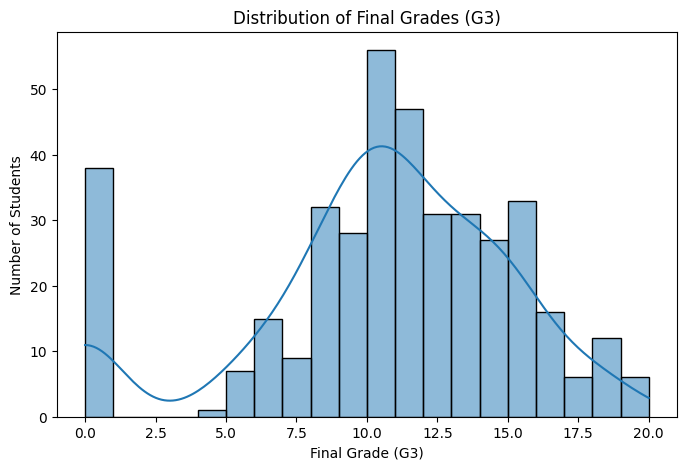

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

In [14]:
df["G3"].describe()

,G3
count,395.000000
mean,10.415190
std,4.581443
min,0.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,20.000000


In [15]:
print("Mean G3:", df["G3"].mean())
print("Median G3:", df["G3"].median())
print("Minimum G3:", df["G3"].min())
print("Maximum G3:", df["G3"].max())

Mean G3: 10.415189873417722
Median G3: 11.0
Minimum G3: 0
Maximum G3: 20


In [16]:
df["G3"].value_counts().sort_index()

,count
G3,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


In [17]:
studytime_g3 = df.groupby("studytime")["G3"].mean()

print(studytime_g3)

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


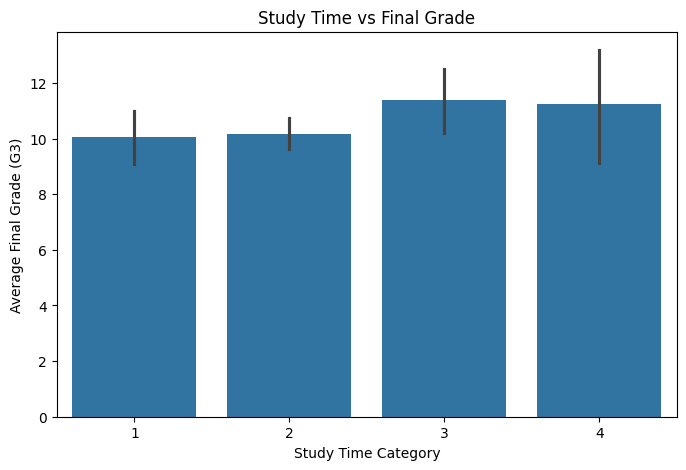

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [19]:
failures_g3 = df.groupby("failures")["G3"].mean()

print(failures_g3)

failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64


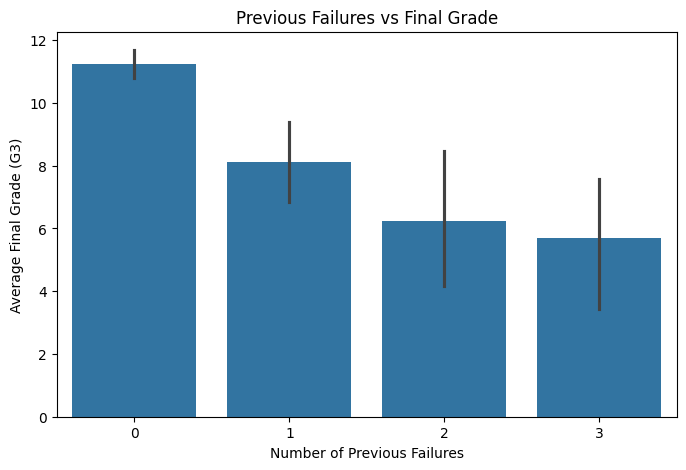

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(x="failures", y="G3", data=df)

plt.title("Previous Failures vs Final Grade")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [21]:
print("Correlation between absences and G3:",
      df["absences"].corr(df["G3"]))

Correlation between absences and G3: 0.03424731615006931


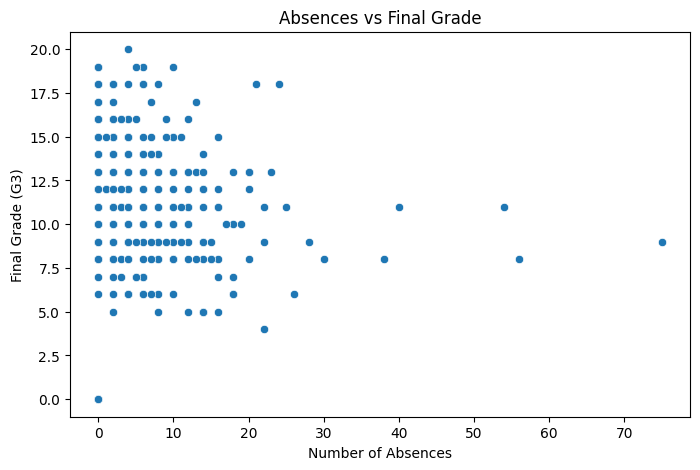

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x="absences", y="G3", data=df)

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.show()

In [23]:
numerical_cols = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "G3"
]

correlation_with_g3 = df[numerical_cols].corr()["G3"].sort_values(ascending=False)

print(correlation_with_g3)

G3           1.000000
G2           0.904868
G1           0.801468
studytime    0.097820
absences     0.034247
age         -0.161579
failures    -0.360415
Name: G3, dtype: float64


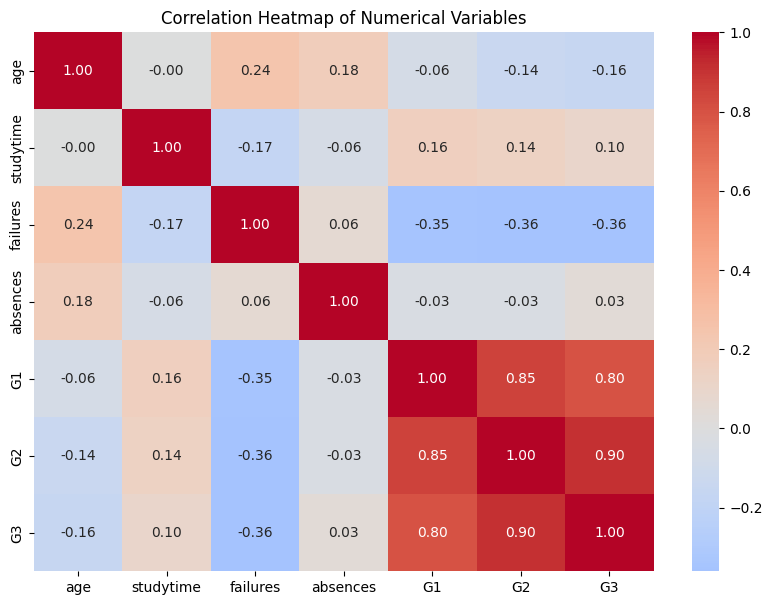

In [24]:
correlation = df[numerical_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

In [25]:
gender_g3 = df.groupby("sex")["G3"].mean()

print(gender_g3)

sex
F     9.966346
M    10.914439
Name: G3, dtype: float64


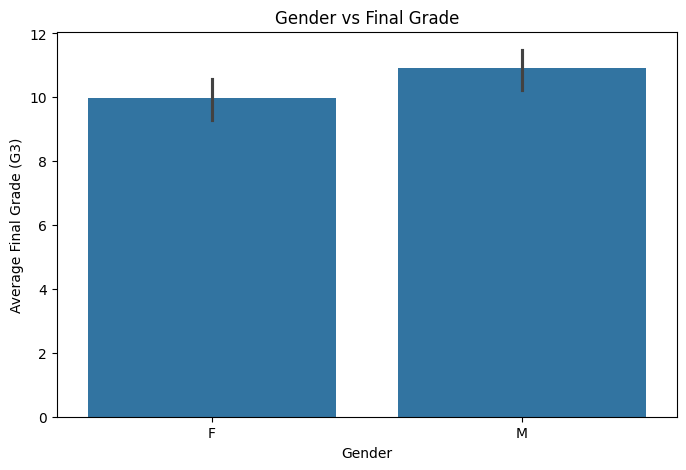

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(x="sex", y="G3", data=df)

plt.title("Gender vs Final Grade")
plt.xlabel("Gender")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [27]:
school_g3 = df.groupby("school")["G3"].mean()

print(school_g3)

school
GP    10.489971
MS     9.847826
Name: G3, dtype: float64


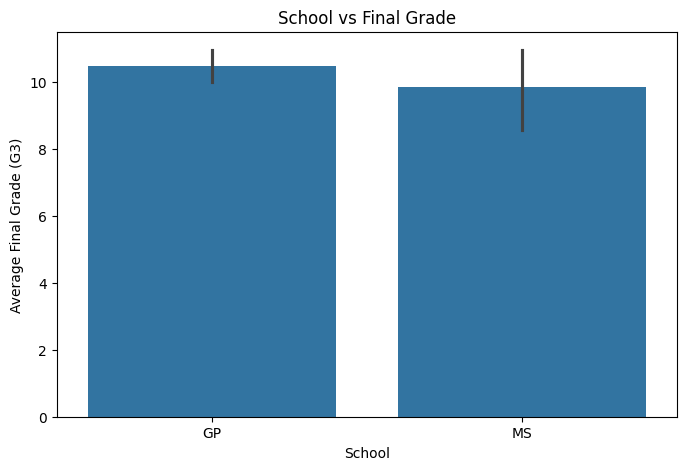

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(x="school", y="G3", data=df)

plt.title("School vs Final Grade")
plt.xlabel("School")
plt.ylabel("Average Final Grade (G3)")

plt.show()

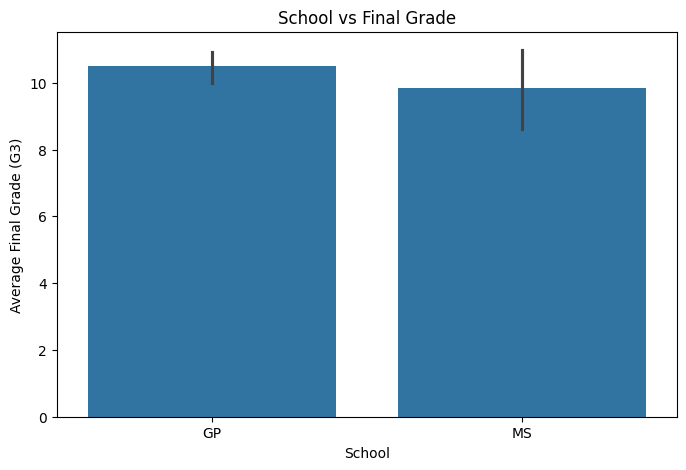

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(x="school", y="G3", data=df)

plt.title("School vs Final Grade")
plt.xlabel("School")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [30]:
internet_g3 = df.groupby("internet")["G3"].mean()

print(internet_g3)

internet
no      9.409091
yes    10.617021
Name: G3, dtype: float64


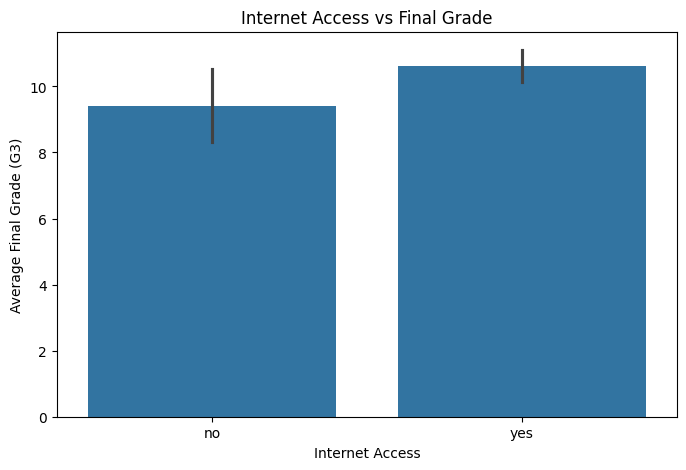

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(x="internet", y="G3", data=df)

plt.title("Internet Access vs Final Grade")
plt.xlabel("Internet Access")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [32]:
higher_g3 = df.groupby("higher")["G3"].mean()

print(higher_g3)

higher
no      6.800
yes    10.608
Name: G3, dtype: float64


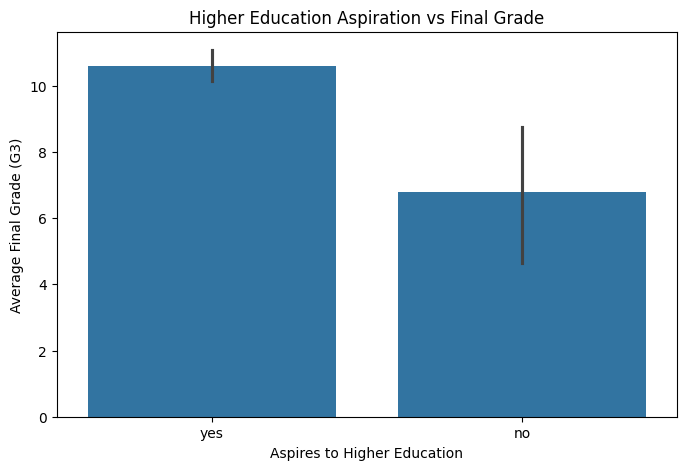

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(x="higher", y="G3", data=df)

plt.title("Higher Education Aspiration vs Final Grade")
plt.xlabel("Aspires to Higher Education")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [34]:
guardian_g3 = df.groupby("guardian")["G3"].mean()

print(guardian_g3)

guardian
father    10.688889
mother    10.483516
other      9.062500
Name: G3, dtype: float64


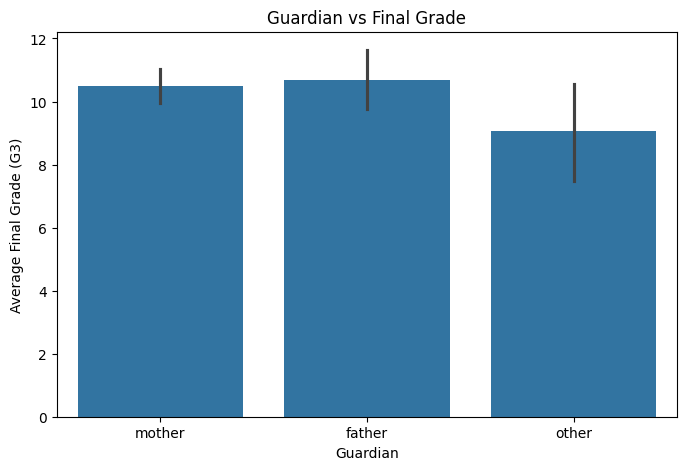

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(x="guardian", y="G3", data=df)

plt.title("Guardian vs Final Grade")
plt.xlabel("Guardian")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [36]:
activities_g3 = df.groupby("activities")["G3"].mean()

print(activities_g3)

activities
no     10.340206
yes    10.487562
Name: G3, dtype: float64


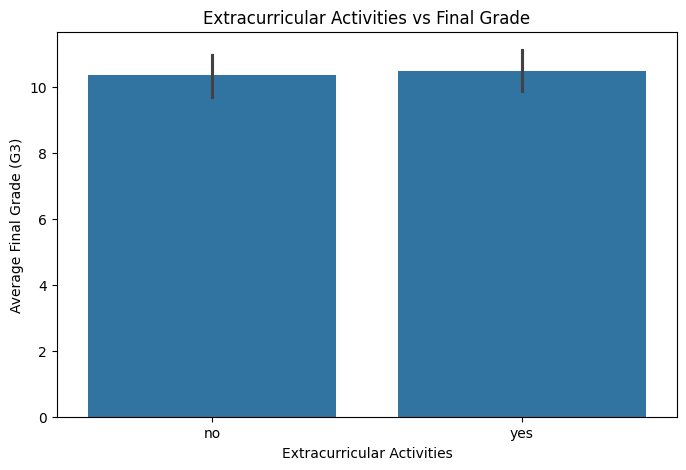

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(x="activities", y="G3", data=df)

plt.title("Extracurricular Activities vs Final Grade")
plt.xlabel("Extracurricular Activities")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [38]:
dalc_g3 = df.groupby("Dalc")["G3"].mean()

print(dalc_g3)

Dalc
1    10.731884
2     9.253333
3    10.500000
4     9.888889
5    10.666667
Name: G3, dtype: float64


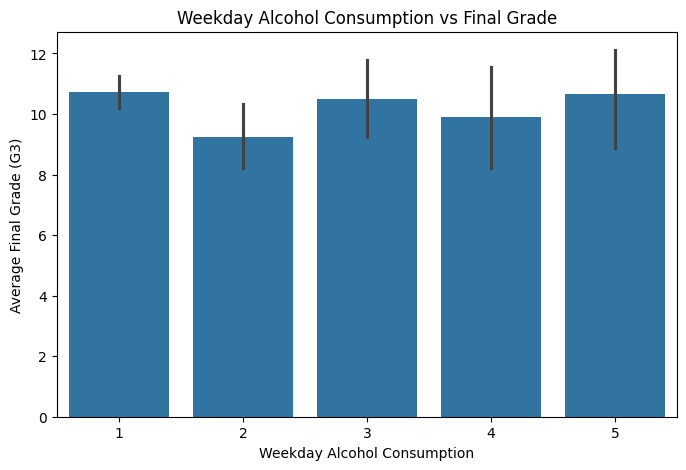

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(x="Dalc", y="G3", data=df)

plt.title("Weekday Alcohol Consumption vs Final Grade")
plt.xlabel("Weekday Alcohol Consumption")
plt.ylabel("Average Final Grade (G3)")

plt.show()

In [40]:
print("Number of students with G3 = 0:", (df["G3"] == 0).sum())

Number of students with G3 = 0: 38


In [41]:
zero_g3 = df[df["G3"] == 0]

print(zero_g3[["G1", "G2", "G3"]].describe())

              G1         G2    G3
count  38.000000  38.000000  38.0
mean    7.526316   4.657895   0.0
std     1.811925   3.700083   0.0
min     4.000000   0.000000   0.0
25%     6.000000   0.000000   0.0
50%     7.000000   5.000000   0.0
75%     9.000000   8.000000   0.0
max    12.000000  10.000000   0.0


In [42]:
import os

os.makedirs("visualizations", exist_ok=True)

print("Visualizations folder created successfully.")

Visualizations folder created successfully.


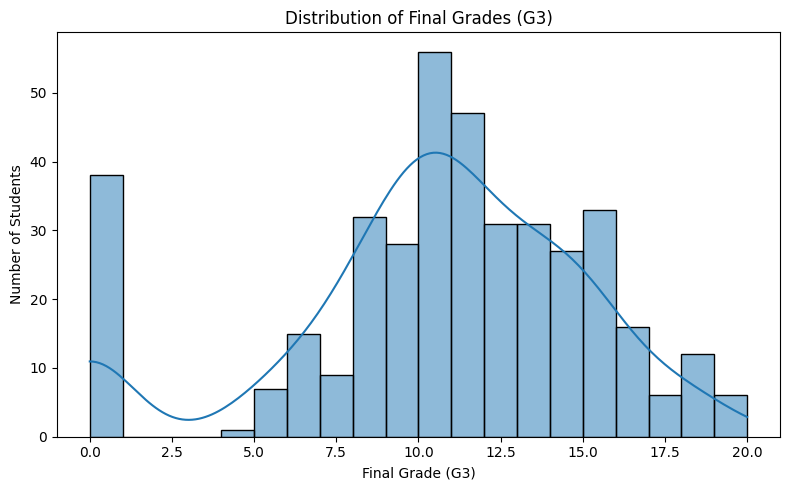

In [43]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("visualizations/g3_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

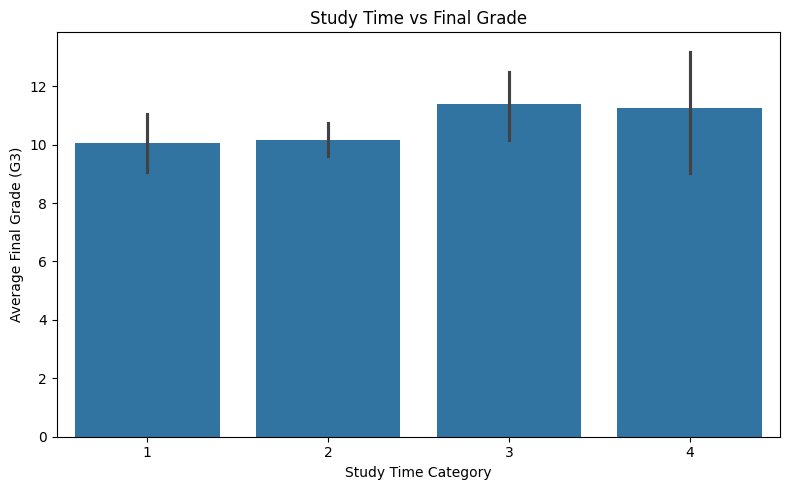

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(x="studytime", y="G3", data=df)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/studytime_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

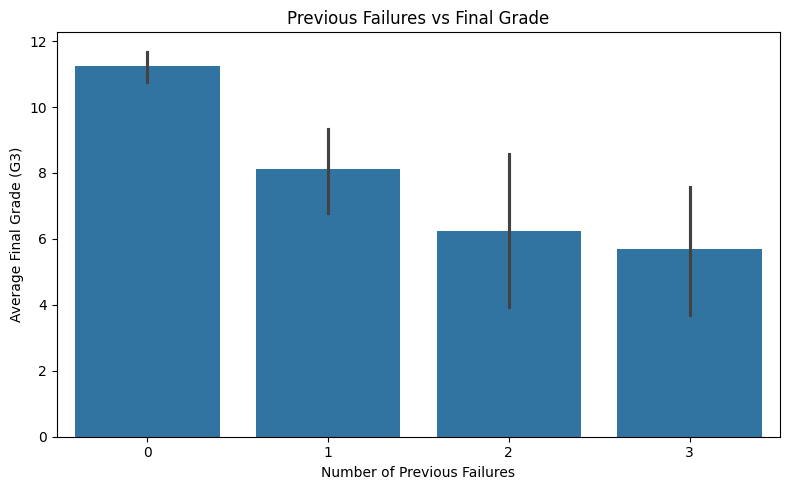

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(x="failures", y="G3", data=df)

plt.title("Previous Failures vs Final Grade")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/failures_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

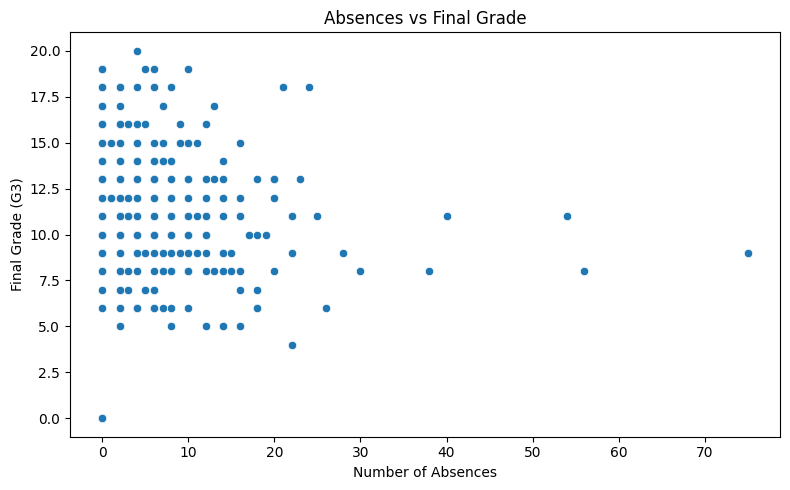

In [46]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x="absences", y="G3", data=df)

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/absences_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

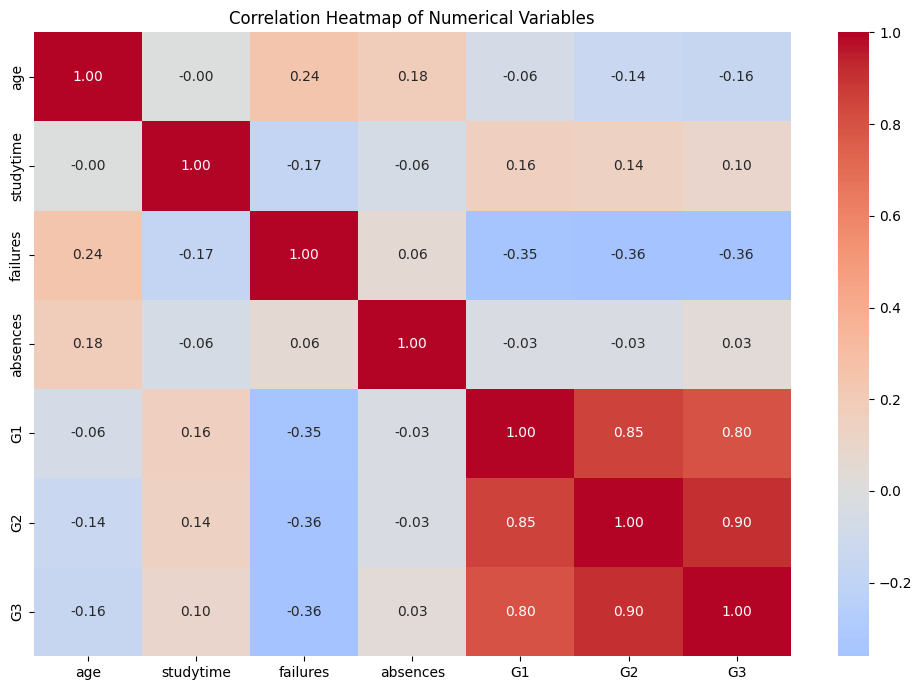

In [47]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.tight_layout()
plt.savefig("visualizations/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

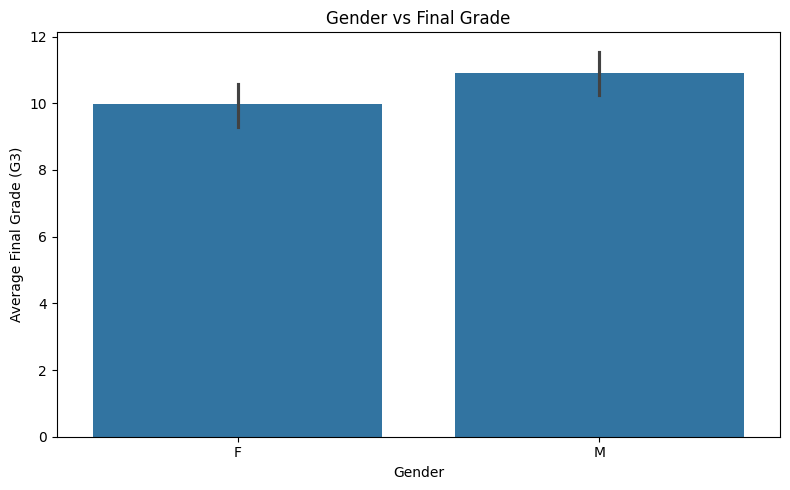

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(x="sex", y="G3", data=df)

plt.title("Gender vs Final Grade")
plt.xlabel("Gender")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/sex_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

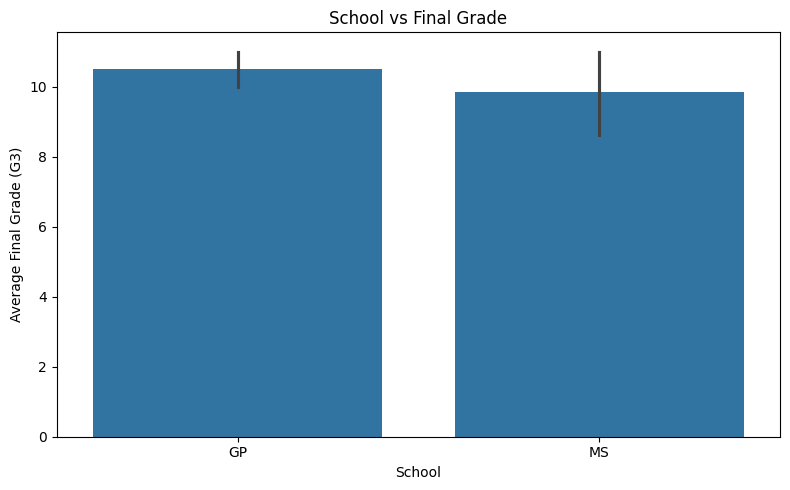

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(x="school", y="G3", data=df)

plt.title("School vs Final Grade")
plt.xlabel("School")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/school_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

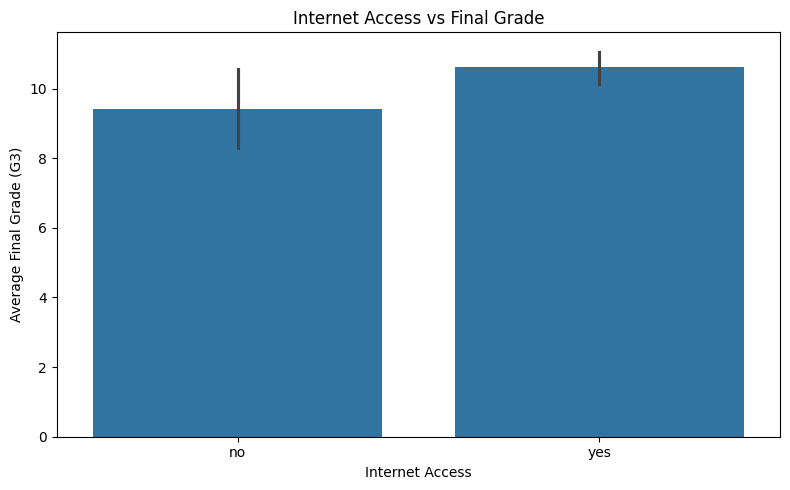

In [50]:
plt.figure(figsize=(8, 5))

sns.barplot(x="internet", y="G3", data=df)

plt.title("Internet Access vs Final Grade")
plt.xlabel("Internet Access")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/internet_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

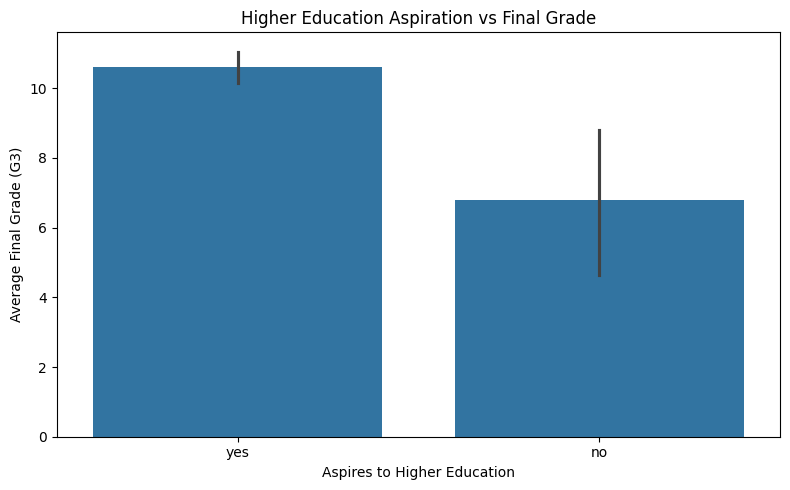

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(x="higher", y="G3", data=df)

plt.title("Higher Education Aspiration vs Final Grade")
plt.xlabel("Aspires to Higher Education")
plt.ylabel("Average Final Grade (G3)")

plt.tight_layout()
plt.savefig("visualizations/higher_vs_g3.png", dpi=300, bbox_inches="tight")
plt.show()

# Key Findings

1. The average final grade (G3) is approximately 10.42, with grades ranging from 0 to 20.

2. G2 has the strongest positive correlation with G3 (0.90), followed by G1 (0.80).

3. Previous failures have a negative relationship with final grades. Students with more previous failures tend to have lower average G3 scores.

4. Study time shows a small positive relationship with final grade, although the differences between some study-time categories are relatively small.

5. Absences have a very weak linear relationship with G3, with a correlation of approximately 0.03.

6. Average final grades differ between demographic groups such as gender and school in this dataset.

7. Students with internet access have a higher average G3 than students without internet access.

8. Students who aspire to higher education have a higher average G3 than students who do not report this aspiration.

9. Guardian categories show differences in average final grades, while extracurricular activities show only a small difference.

10. Weekday alcohol-consumption categories show variation in average G3, but there is no simple increasing or decreasing pattern.

11. The dataset contains 38 students with G3 = 0. Their earlier grades, particularly G2, are generally lower, so these records should be investigated as a potential data-quality issue rather than automatically removed.

12. These findings describe associations in the dataset and should not be interpreted as proof that any particular factor causes changes in final grades.

# Conclusion

The exploratory analysis shows that students' earlier-period grades, especially G2 and G1, have the strongest relationships with final grade G3. Previous failures are negatively associated with final grades, while study time shows a smaller positive association. Several demographic, educational, family, and lifestyle variables also show differences in average final grades across groups.

The analysis also identified 38 students with a final grade of 0. Their earlier grades tend to be lower, so these observations should be considered during interpretation rather than automatically treated as errors.

Overall, the analysis highlights important patterns and potential data issues in the Student Performance dataset. The results are descriptive and show associations rather than causal relationships.